# Proyek Analisis Data: Bike Sharing Analysis
- **Nama:** Bethelina Imanuella Yesaya
- **Email:** bethelinaiy226@gmail.com
- **ID Dicoding:** beth226

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pola jumlah penyewaan sepeda berdasarkan jam dalam sehari, serta bagaimana perbedaannya antara hari kerja dan hari nonkerja selama 2011–2012?
- **Pertanyaan 2:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan musim dan kondisi cuaca selama 2011–2012?

## Import Semua Packages/Library yang Digunakan

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

In [15]:
from google.colab import files

uploaded = files.upload()

Saving day.csv to day (1).csv
Saving hour.csv to hour (1).csv


#### Load df Bike Sharing

In [16]:
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

print("Jumlah data harian:", day_df.shape)
print("Jumlah data per jam:", hour_df.shape)

display(day_df.head())
display(hour_df.head())

Jumlah data harian: (731, 16)
Jumlah data per jam: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset terdiri dari dua data utama, yaitu day_df dengan 731 baris dan 16 kolom yang mencatat data penyewaan sepeda harian, serta hour_df dengan 17.379 baris dan 17 kolom yang mencatat data penyewaan sepeda per jam.
- Kedua dataset mencakup periode 1 Januari 2011 hingga 31 Desember 2012. Dataset menyediakan informasi mengenai jumlah penyewaan sepeda (cnt), waktu, hari kerja, musim, dan kondisi cuaca yang dapat digunakan untuk menganalisis pola penyewaan sepeda.

### Assessing Data

#### Identifying Data Quality Issues

In [17]:
# Memeriksa informasi dataset
print("Informasi day_df:")
day_df.info()

print("\nInformasi hour_df:")
hour_df.info()

# Memeriksa missing values
print("\nMissing values day_df:")
display(day_df.isnull().sum())

print("\nMissing values hour_df:")
display(hour_df.isnull().sum())

# Memeriksa data duplikat
print("\nJumlah duplikat day_df:", day_df.duplicated().sum())
print("Jumlah duplikat hour_df:", hour_df.duplicated().sum())

# Statistik deskriptif
display(day_df.describe())
display(hour_df.describe())

# Memeriksa rentang nilai kategori
print("Nilai season:", sorted(day_df["season"].unique()))
print("Nilai weathersit:", sorted(day_df["weathersit"].unique()))
print("Nilai workingday:", sorted(hour_df["workingday"].unique()))
print("Rentang jam:", sorted(hour_df["hr"].unique()))

# Memeriksa rentang tanggal
print("Rentang tanggal day_df:",
      day_df["dteday"].min(), "sampai", day_df["dteday"].max())

print("Rentang tanggal hour_df:",
      hour_df["dteday"].min(), "sampai", hour_df["dteday"].max())

Informasi day_df:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Informasi hour_df:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0



Missing values hour_df:


,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0



Jumlah duplikat day_df: 0
Jumlah duplikat hour_df: 0


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


Nilai season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Nilai weathersit: [np.int64(1), np.int64(2), np.int64(3)]
Nilai workingday: [np.int64(0), np.int64(1)]
Rentang jam: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]
Rentang tanggal day_df: 2011-01-01 sampai 2012-12-31
Rentang tanggal hour_df: 2011-01-01 sampai 2012-12-31


**Steps to Take:**
- Mengubah tipe data kolom dteday pada kedua dataset dari object menjadi datetime agar dapat digunakan untuk pengolahan dan analisis berdasarkan waktu.
- Memastikan kembali kualitas data setelah proses pembersihan, termasuk memeriksa nilai kosong dan duplikasi. Karena tidak ditemukan missing values maupun data duplikat pada tahap pemeriksaan awal, penghapusan data atau pengisian nilai kosong tidak diperlukan.

**Insight:** (Opsional)
- Kedua dataset tidak memiliki missing values maupun baris duplikat, sehingga tidak ditemukan masalah terkait kelengkapan data dan duplikasi pada pemeriksaan awal.
- Kolom dteday masih memiliki tipe data object, sehingga perlu dikonversi menjadi datetime agar mendukung analisis berbasis tanggal. Selain itu, rentang jam pada hour_df mencakup seluruh jam, yaitu 0–23, sehingga data dapat digunakan untuk mengeksplorasi pola penyewaan sepeda berdasarkan waktu.

### Cleaning Data

#### Fixing Data Quality Issues

In [18]:
# Membuat salinan dataset agar data awal tetap tersedia
day_df = day_df.copy()
hour_df = hour_df.copy()

# Mengubah tipe data tanggal menjadi datetime
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# Memeriksa hasil cleaning
print("Tipe data tanggal day_df:", day_df["dteday"].dtype)
print("Tipe data tanggal hour_df:", hour_df["dteday"].dtype)

print("\nTotal missing values day_df:",
      day_df.isnull().sum().sum())
print("Total missing values hour_df:",
      hour_df.isnull().sum().sum())

print("\nJumlah duplikat day_df:", day_df.duplicated().sum())
print("Jumlah duplikat hour_df:", hour_df.duplicated().sum())

print("\nUkuran day_df setelah cleaning:", day_df.shape)
print("Ukuran hour_df setelah cleaning:", hour_df.shape)

Tipe data tanggal day_df: datetime64[ns]
Tipe data tanggal hour_df: datetime64[ns]

Total missing values day_df: 0
Total missing values hour_df: 0

Jumlah duplikat day_df: 0
Jumlah duplikat hour_df: 0

Ukuran day_df setelah cleaning: (731, 16)
Ukuran hour_df setelah cleaning: (17379, 17)


**Insight:** (Opsional)
- Kolom dteday pada day_df dan hour_df berhasil dikonversi dari tipe data object menjadi datetime64[ns], sehingga data tanggal siap digunakan untuk analisis berbasis waktu.
- Setelah proses cleaning, kedua dataset tetap memiliki 0 missing values dan 0 data duplikat. Ukuran dataset juga tidak berubah, yaitu 731 baris dan 16 kolom pada day_df, serta 17.379 baris dan 17 kolom pada hour_df. Dengan demikian, tidak ada baris data yang perlu dihapus dan dataset siap digunakan untuk tahap analisis berikutnya.

## Exploratory Data Analysis (EDA)

### Explore Bike Rental Patterns and Influencing Factors

In [19]:
# 1. Statistik deskriptif jumlah penyewaan sepeda
print("Statistik penyewaan sepeda harian:")
display(day_df[["casual", "registered", "cnt"]].describe())

print("Statistik penyewaan sepeda per jam:")
display(hour_df[["casual", "registered", "cnt"]].describe())


# 2. Rata-rata penyewaan berdasarkan musim
season_summary = (
    day_df.groupby("season")["cnt"]
    .agg(["mean", "median", "sum", "count"])
    .round(2)
)

print("Penyewaan sepeda berdasarkan musim:")
display(season_summary)


# 3. Rata-rata penyewaan berdasarkan kondisi cuaca
weather_summary = (
    day_df.groupby("weathersit")["cnt"]
    .agg(["mean", "median", "sum", "count"])
    .round(2)
)

print("Penyewaan sepeda berdasarkan kondisi cuaca:")
display(weather_summary)


# 4. Rata-rata penyewaan berdasarkan jam
hour_summary = (
    hour_df.groupby("hr")["cnt"]
    .mean()
    .round(2)
)

print("Rata-rata penyewaan sepeda berdasarkan jam:")
display(hour_summary)


# 5. Rata-rata penyewaan berdasarkan jam dan jenis hari
workingday_summary = (
    hour_df.groupby(["hr", "workingday"])["cnt"]
    .mean()
    .unstack()
    .round(2)
)

workingday_summary.columns = ["Hari Nonkerja", "Hari Kerja"]

print("Penyewaan berdasarkan jam dan jenis hari:")
display(workingday_summary)

Statistik penyewaan sepeda harian:


,casual,registered,cnt
count,731.000000,731.000000,731.000000
mean,848.176471,3656.172367,4504.348837
std,686.622488,1560.256377,1937.211452
min,2.000000,20.000000,22.000000
25%,315.500000,2497.000000,3152.000000
50%,713.000000,3662.000000,4548.000000
75%,1096.000000,4776.500000,5956.000000
max,3410.000000,6946.000000,8714.000000


Statistik penyewaan sepeda per jam:


,casual,registered,cnt
count,17379.000000,17379.000000,17379.000000
mean,35.676218,153.786869,189.463088
std,49.305030,151.357286,181.387599
min,0.000000,0.000000,1.000000
25%,4.000000,34.000000,40.000000
50%,17.000000,115.000000,142.000000
75%,48.000000,220.000000,281.000000
max,367.000000,886.000000,977.000000


Penyewaan sepeda berdasarkan musim:


...

,mean,median,sum,count
weathersit,,,,
1,4876.79,4844.0,2257952,463
2,4035.86,4040.0,996858,247
3,1803.29,1817.0,37869,21


Rata-rata penyewaan sepeda berdasarkan jam:


,cnt
hr,
0,53.90
1,33.38
2,22.87
3,11.73
4,6.35
5,19.89
6,76.04
7,212.06
8,359.01


Penyewaan berdasarkan jam dan jenis hari:


,Hari Nonkerja,Hari Kerja
hr,,
0,90.80,36.79
1,69.51,16.55
2,53.17,8.68
3,25.78,4.94
4,8.26,5.43
5,8.69,24.91
6,18.74,102.50
7,43.41,290.61
8,105.65,477.01


**Insight:** (Opsional)
- Berdasarkan statistik deskriptif, rata-rata penyewaan sepeda harian mencapai 4.504 unit, sedangkan rata-rata penyewaan per jam mencapai 189 unit. Jumlah penyewaan didominasi oleh pengguna terdaftar (registered), dengan rata-rata 3.656 pengguna per hari dan 154 pengguna per jam, lebih tinggi dibandingkan pengguna kasual (casual).
- Berdasarkan musim, rata-rata penyewaan tertinggi terdapat pada musim 3, yaitu 5.644 unit per hari, sedangkan rata-rata terendah terdapat pada musim 1, yaitu 2.604 unit per hari.
- Berdasarkan kondisi cuaca, rata-rata penyewaan tertinggi terjadi pada kondisi cuaca 1 sebesar 4.877 unit per hari, diikuti kondisi cuaca 2 sebesar 4.036 unit dan kondisi cuaca 3 sebesar 1.803 unit per hari. Hal ini menunjukkan bahwa jumlah penyewaan cenderung lebih tinggi pada kondisi cuaca yang lebih baik.
- Berdasarkan jam, rata-rata penyewaan tertinggi secara keseluruhan terjadi pada pukul 17.00 sebesar 461 unit, sedangkan rata-rata terendah terjadi pada pukul 04.00 sebesar 6 unit.
- Pola penyewaan berbeda antara hari kerja dan hari nonkerja. Pada hari kerja, penyewaan mencapai puncak pada pukul 08.00 sebesar 477 unit dan pukul 17.00 sebesar 525 unit. Sementara itu, pada hari nonkerja, penyewaan tertinggi terjadi pada pukul 13.00 sebesar 373 unit. Pola ini mengindikasikan bahwa penyewaan pada hari kerja lebih terkonsentrasi pada jam berangkat dan pulang kerja, sedangkan pada hari nonkerja penyewaan cenderung tinggi pada siang hari.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

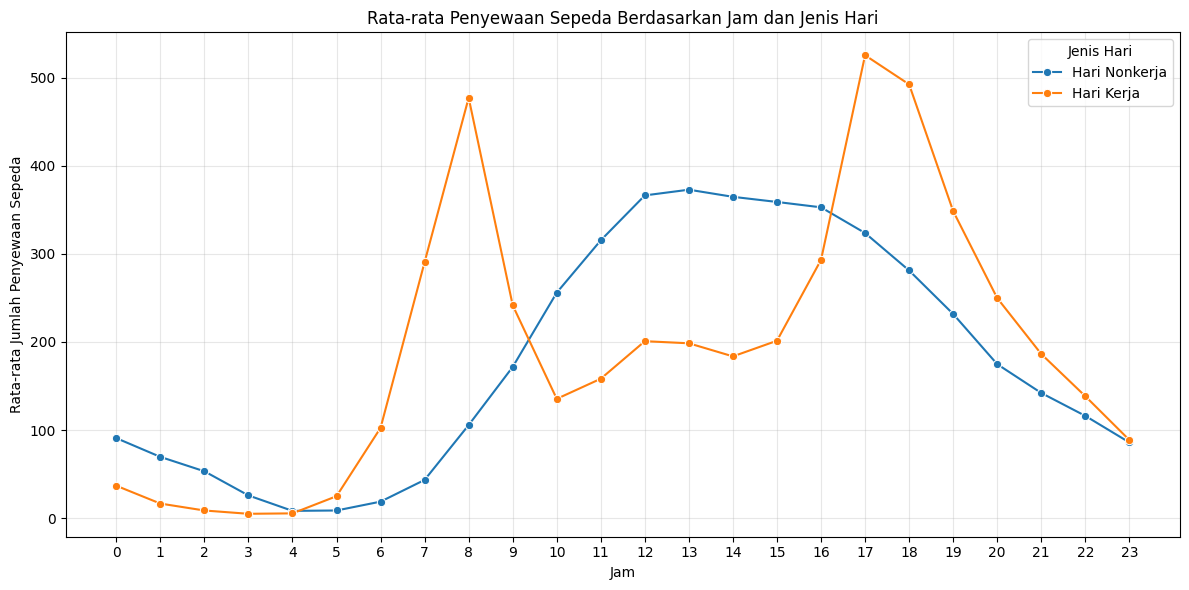

In [20]:
# Menghitung rata-rata penyewaan berdasarkan jam dan jenis hari
hourly_by_day = (
    hour_df.groupby(["hr", "workingday"])["cnt"]
    .mean()
    .reset_index()
)

hourly_by_day["Jenis Hari"] = hourly_by_day["workingday"].map({
    0: "Hari Nonkerja",
    1: "Hari Kerja"
})

# Membuat visualisasi
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_by_day,
    x="hr",
    y="cnt",
    hue="Jenis Hari",
    marker="o"
)

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Jam dan Jenis Hari")
plt.xlabel("Jam")
plt.ylabel("Rata-rata Jumlah Penyewaan Sepeda")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.legend(title="Jenis Hari")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Grafik menunjukkan bahwa pola penyewaan sepeda berbeda antara hari kerja dan hari nonkerja. Pada hari kerja, terdapat dua puncak penyewaan, yaitu pukul 08.00 dengan rata-rata sekitar 477 penyewaan dan pukul 17.00 dengan rata-rata sekitar 525 penyewaan. Pola ini mengindikasikan adanya peningkatan penggunaan sepeda pada jam berangkat dan pulang kerja.
- Pada hari nonkerja, penyewaan meningkat sejak pagi dan mencapai puncak pada pukul 13.00 dengan rata-rata sekitar 373 penyewaan. Jumlah penyewaan relatif tinggi selama siang hingga sore hari, yang menunjukkan pola penggunaan berbeda dibandingkan hari kerja.

### Pertanyaan 2:

/tmp/ipykernel_737/3547559389.py:22: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


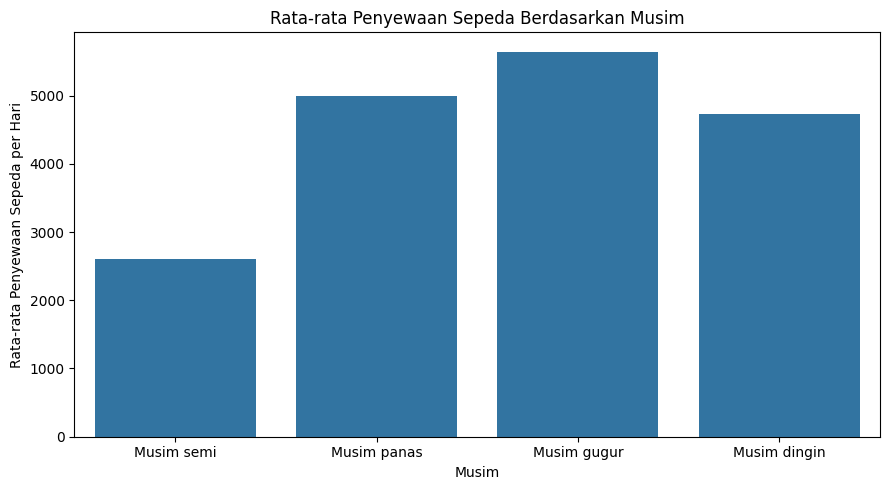

In [21]:
# Grafik A - Berdasarkan musim
# Memberikan label musim
season_labels = {
    1: "Musim semi",
    2: "Musim panas",
    3: "Musim gugur",
    4: "Musim dingin"
}

season_plot = day_df.copy()
season_plot["Musim"] = season_plot["season"].map(season_labels)

season_order = [
    "Musim semi",
    "Musim panas",
    "Musim gugur",
    "Musim dingin"
]

plt.figure(figsize=(9, 5))

sns.barplot(
    data=season_plot,
    x="Musim",
    y="cnt",
    order=season_order,
    ci=None
)

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Musim")
plt.xlabel("Musim")
plt.ylabel("Rata-rata Penyewaan Sepeda per Hari")
plt.tight_layout()
plt.show()

/tmp/ipykernel_737/2116084892.py:22: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


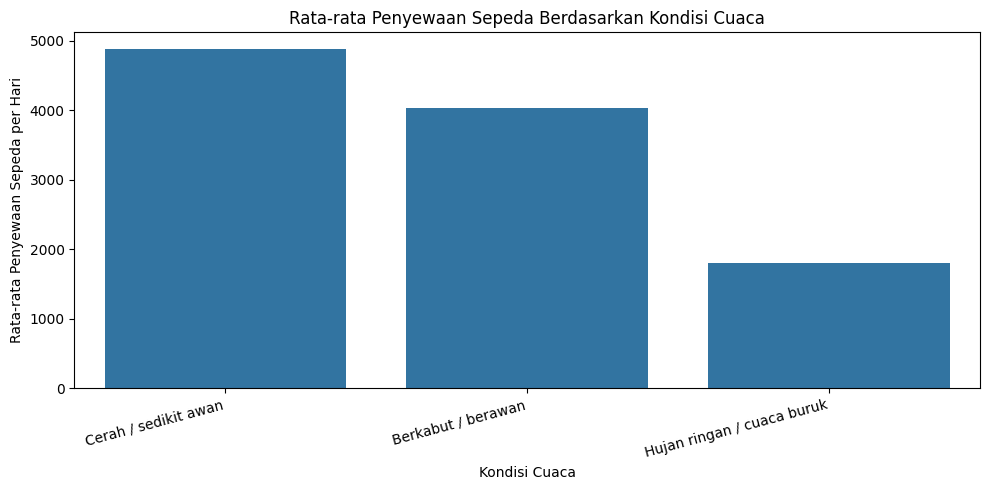

In [22]:
# Grafik B - Berdasarkan kondisi cuaca
# Memberikan label kondisi cuaca
weather_labels = {
    1: "Cerah / sedikit awan",
    2: "Berkabut / berawan",
    3: "Hujan ringan / cuaca buruk"
}

weather_plot = day_df.copy()
weather_plot["Kondisi Cuaca"] = (
    weather_plot["weathersit"].map(weather_labels)
)

weather_order = [
    "Cerah / sedikit awan",
    "Berkabut / berawan",
    "Hujan ringan / cuaca buruk"
]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=weather_plot,
    x="Kondisi Cuaca",
    y="cnt",
    order=weather_order,
    ci=None
)

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca")
plt.xlabel("Kondisi Cuaca")
plt.ylabel("Rata-rata Penyewaan Sepeda per Hari")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Grafik musim menunjukkan bahwa rata-rata penyewaan tertinggi terjadi pada musim gugur (musim 3), yaitu sekitar 5.644 penyewaan per hari, diikuti musim panas (musim 2) sebesar 4.992, musim dingin (musim 4) sebesar 4.728, dan musim semi (musim 1) sebesar 2.604. Hal ini menunjukkan bahwa jumlah penyewaan bervariasi antarmusim, dengan perbedaan tertinggi dan terendah sekitar 3.040 penyewaan per hari.
- Grafik cuaca menunjukkan bahwa rata-rata penyewaan tertinggi terjadi pada kondisi cerah atau sedikit berawan, yaitu sekitar 4.877 penyewaan per hari. Rata-rata tersebut menurun menjadi sekitar 4.036 saat berkabut atau berawan dan sekitar 1.803 saat hujan ringan atau kondisi cuaca buruk. Dengan demikian, penyewaan cenderung lebih tinggi pada kondisi cuaca yang lebih baik.

## Analisis Lanjutan (Opsional)

In [23]:
# Menghitung rata-rata penyewaan berdasarkan jenis pengguna
# Membandingkan rata-rata penyewaan pengguna casual dan registered
user_type_summary = (
    hour_df.groupby("workingday")[["casual", "registered", "cnt"]]
    .mean()
    .round(2)
)

user_type_summary.index = user_type_summary.index.map({
    0: "Hari Nonkerja",
    1: "Hari Kerja"
})

print("Rata-rata penyewaan berdasarkan jenis pengguna dan hari:")
display(user_type_summary)

# Menghitung proporsi pengguna casual dari total rata-rata penyewaan
user_type_summary["Persentase Casual (%)"] = (
    user_type_summary["casual"] / user_type_summary["cnt"] * 100
).round(2)

user_type_summary["Persentase Registered (%)"] = (
    user_type_summary["registered"] / user_type_summary["cnt"] * 100
).round(2)

print("Proporsi rata-rata penyewaan berdasarkan jenis pengguna:")
display(
    user_type_summary[
        ["Persentase Casual (%)", "Persentase Registered (%)"]
    ]
)

Rata-rata penyewaan berdasarkan jenis pengguna dan hari:


,casual,registered,cnt
workingday,,,
Hari Nonkerja,57.44,123.96,181.41
Hari Kerja,25.56,167.65,193.21


Proporsi rata-rata penyewaan berdasarkan jenis pengguna:


,Persentase Casual (%),Persentase Registered (%)
workingday,,
Hari Nonkerja,31.66,68.33
Hari Kerja,13.23,86.77


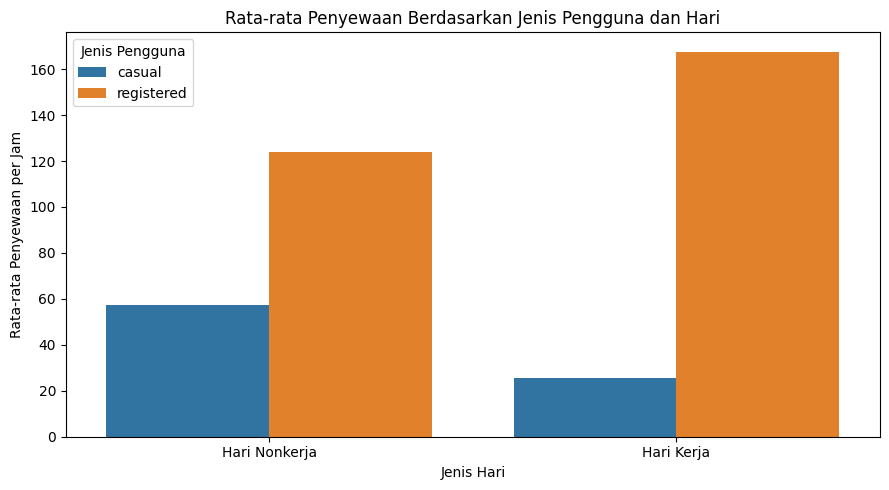

In [24]:
# Membuat visualisasi
# Menyiapkan data untuk visualisasi
user_type_plot = (
    hour_df.groupby("workingday")[["casual", "registered"]]
    .mean()
    .reset_index()
    .melt(
        id_vars="workingday",
        var_name="Jenis Pengguna",
        value_name="Rata-rata Penyewaan"
    )
)

user_type_plot["Jenis Hari"] = user_type_plot["workingday"].map({
    0: "Hari Nonkerja",
    1: "Hari Kerja"
})

plt.figure(figsize=(9, 5))

sns.barplot(
    data=user_type_plot,
    x="Jenis Hari",
    y="Rata-rata Penyewaan",
    hue="Jenis Pengguna",
    errorbar=None
)

plt.title("Rata-rata Penyewaan Berdasarkan Jenis Pengguna dan Hari")
plt.xlabel("Jenis Hari")
plt.ylabel("Rata-rata Penyewaan per Jam")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pengguna terdaftar (registered) memiliki rata-rata penyewaan yang lebih tinggi dibandingkan pengguna kasual (casual), baik pada hari kerja maupun hari nonkerja. Pada hari kerja, rata-rata penyewaan pengguna terdaftar mencapai 167,65 unit per jam, sedangkan pengguna kasual sebesar 25,56 unit per jam.
- Pengguna kasual menunjukkan rata-rata penyewaan yang lebih tinggi pada hari nonkerja, yaitu 57,44 unit per jam, dibandingkan 25,56 unit per jam pada hari kerja. Sebaliknya, pengguna terdaftar memiliki rata-rata penyewaan lebih tinggi pada hari kerja, yaitu 167,65 unit per jam, dibandingkan 123,96 unit per jam pada hari nonkerja.
- Proporsi pengguna terdaftar mencapai 86,77% dari rata-rata penyewaan pada hari kerja, sedangkan proporsi pengguna kasual meningkat menjadi 31,66% pada hari nonkerja. Pola ini menunjukkan bahwa pengguna terdaftar lebih dominan pada hari kerja, sementara kontribusi pengguna kasual relatif lebih besar pada hari nonkerja.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pola penyewaan sepeda berbeda antara hari kerja dan hari nonkerja. Pada hari kerja, rata-rata penyewaan mencapai puncak pukul 17.00 sebesar 525,29 unit per jam, dengan puncak lainnya pada pukul 08.00 sebesar 477,01 unit per jam. Sementara itu, pada hari nonkerja, rata-rata penyewaan tertinggi terjadi pukul 13.00 sebesar 372,73 unit per jam. Hasil ini menunjukkan bahwa waktu dengan permintaan tertinggi berbeda berdasarkan jenis hari, sehingga pengelolaan ketersediaan sepeda perlu mempertimbangkan pola waktu tersebut.
- **Conclusion pertanyaan 2:** Rata-rata penyewaan sepeda bervariasi berdasarkan musim dan kondisi cuaca. Penyewaan tertinggi terjadi pada musim gugur (musim 3), sebesar 5.644,30 unit per hari, sedangkan penyewaan terendah terjadi pada musim semi (musim 1), sebesar 2.604,13 unit per hari. Berdasarkan kondisi cuaca, rata-rata penyewaan tertinggi tercatat pada kondisi cerah atau sedikit berawan, yaitu 4.876,79 unit per hari, dan terendah pada kondisi hujan ringan atau cuaca buruk, yaitu 1.803,29 unit per hari. Temuan ini menunjukkan bahwa pola penyewaan berkaitan dengan variasi musim dan kondisi cuaca.
- **Conclusion analisis lanjutan:** Pengguna terdaftar mendominasi penyewaan sepeda pada kedua jenis hari, terutama pada hari kerja dengan proporsi sebesar 86,77%. Rata-rata penyewaan pengguna terdaftar meningkat dari 123,96 unit per jam pada hari nonkerja menjadi 167,65 unit per jam pada hari kerja. Sebaliknya, rata-rata penyewaan pengguna kasual lebih tinggi pada hari nonkerja, yaitu 57,44 unit per jam, dibandingkan 25,56 unit per jam pada hari kerja. Hal ini menunjukkan adanya perbedaan pola penggunaan antara kedua kelompok pengguna yang dapat menjadi dasar penyusunan strategi layanan dan promosi.

**Rekomendasi Action Item:**
- Menambah ketersediaan sepeda di lokasi dengan permintaan tinggi sebelum pukul 08.00 dan pukul 17.00 pada hari kerja, serta menjelang siang pada hari nonkerja. Evaluasi dilakukan dengan memantau data penyewaan per jam dan lokasi.
- Menggunakan data historis untuk memperkirakan kebutuhan sepeda pada musim dengan permintaan tinggi serta menyesuaikan jadwal perawatan dan kesiapan operasional saat cuaca kurang mendukung.
- Menawarkan promosi di luar jam sibuk atau paket penyewaan yang sesuai untuk pengguna kasual agar penggunaan sepeda pada hari kerja dapat meningkat.
- Mengembangkan program loyalitas atau paket berlangganan serta memastikan ketersediaan sepeda pada jam berangkat dan pulang kerja, ketika permintaan dari kelompok ini relatif tinggi.
- Membuat dashboard yang menampilkan jumlah penyewaan, jam sibuk, musim, kondisi cuaca, dan komposisi pengguna untuk membantu evaluasi strategi operasional dan promosi secara berkala.